In [9]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

from utils import load_data

plt.rcParams["figure.figsize"] = (10, 5)
load_data.clear()

df = load_data("data/activities_clean.csv").copy()
print(f"df : {len(df)} sorties, {len(df.columns)} colonnes")

2026-10-13 22:57:43.025 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


df : 131 sorties, 30 colonnes


In [10]:
# Features engineered
df["pause_ratio"] = df["pause_seconds"] / df["moving_time_seconds"]
df["elev_per_km"] = df["total_elevation_gain_m"] / df["distance_km"]

# Trier par date pour les rolling backward
df["date_utc"] = pd.to_datetime(df["start_date_local"], utc=True)
df = df.sort_values("date_utc").reset_index(drop=True)
df["date_only"] = df["date_utc"].dt.floor("D").dt.tz_localize(None)

def rolling_backward(dates, values, days):
    out = np.zeros(len(dates))
    for i in range(len(dates)):
        mask = (dates.values < dates.values[i]) & (dates.values >= dates.values[i] - pd.Timedelta(days=days))
        out[i] = values[mask].sum()
    return out

df["vol_30d_km"] = rolling_backward(df["date_only"], df["distance_km"], 30)
df["days_since_last"] = df["date_only"].diff().dt.days.astype(float)

# Saison (facteur) : pour l'instant on ne la met pas, on commence simple
# df["season"] = df["date_only"].dt.month.map({12:"hiver",1:"hiver",2:"hiver",3:"printemps",...})

print(df[["distance_km", "pace_min_km", "elev_per_km", "pause_ratio",
          "weather_temperature", "weather_humidity",
          "vol_30d_km", "days_since_last"]].describe().round(2))

       distance_km  pace_min_km  elev_per_km  pause_ratio  \
count       131.00       131.00       131.00       131.00   
mean          5.36         5.00         6.27         0.06   
std           4.79         0.79         7.79         0.27   
min           0.29         3.63         0.00         0.00   
25%           2.37         4.40         3.26         0.00   
50%           4.73         4.85         4.24         0.00   
75%           6.36         5.33         5.76         0.02   
max          35.38         7.14        48.99         2.47   

       weather_temperature  weather_humidity  vol_30d_km  days_since_last  
count               131.00            131.00      131.00           130.00  
mean                 16.35             71.08       35.48             6.68  
std                   5.90             14.90       30.23            10.25  
min                   0.20             32.00        0.00             0.00  
25%                  13.50             60.50        9.55             1

Filtres + échantillon de modélisation

In [11]:
# Mêmes filtres que l'ACP v4 : exclut micro-sorties et le long trail
mask = (df["distance_km"] >= 1) & (df["distance_km"] < 30)
dfm = df[mask].copy()

# Check NA sur les variables du modèle
MODEL_VARS = ["pace_min_km", "weather_temperature", "weather_humidity",
              "distance_km", "elev_per_km", "vol_30d_km", "days_since_last"]
print("NA par variable :")
print(dfm[MODEL_VARS].isna().sum())
print(f"\nn modélisation : {len(dfm.dropna(subset=MODEL_VARS))} (sur {len(dfm)})")

NA par variable :
pace_min_km            0
weather_temperature    0
weather_humidity       0
distance_km            0
elev_per_km            0
vol_30d_km             0
days_since_last        1
dtype: int64

n modélisation : 121 (sur 122)


Modèle OLS complet

In [12]:
# T° en polynôme degré 2, humidité séparée
# On ne met PAS season pour l'instant : à discuter avec Quost (confondu avec T° et vol_30d)
formula = (
    "pace_min_km ~ weather_temperature + I(weather_temperature**2) "
    "+ weather_humidity + distance_km + elev_per_km "
    "+ vol_30d_km + days_since_last"
)

model = smf.ols(formula, data=dfm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.182
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     3.581
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00162
Time:                        22:57:43   Log-Likelihood:                -131.93
No. Observations:                 121   AIC:                             279.9
Df Residuals:                     113   BIC:                             302.2
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

VIF (colinéarité)

In [13]:
# VIF sur les prédicteurs (hors intercept, hors terme polynomial)
# On ajoute T² à la main pour voir le VIF du polynôme
X = dfm[["weather_temperature", "weather_humidity", "distance_km",
         "elev_per_km", "vol_30d_km", "days_since_last"]].dropna().copy()
X["T2"] = X["weather_temperature"]**2
X = sm.add_constant(X)

vif = pd.DataFrame({
    "var": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif.round(2))

                   var     VIF
0                const  104.56
1  weather_temperature   13.40
2     weather_humidity    1.88
3          distance_km    1.06
4          elev_per_km    1.09
5           vol_30d_km    1.38
6      days_since_last    1.32
7                   T2   13.61


Diagnostics résidus

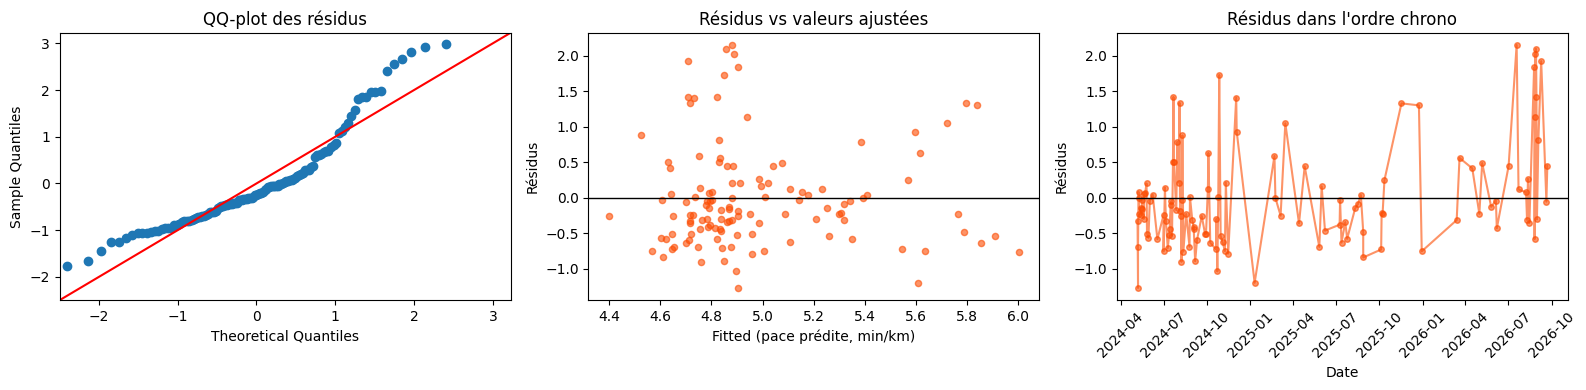


Durbin-Watson : 1.545  (2 = pas d'autocorrelation)
R² ajusté : 0.131
RMSE pace : 0.745 min/km = 44.7 s/km


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# QQ-plot
sm.qqplot(model.resid, line="45", fit=True, ax=axes[0])
axes[0].set_title("QQ-plot des résidus")

# Résidus vs fitted
axes[1].scatter(model.fittedvalues, model.resid, alpha=0.6, s=20, color="#FC4C02")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Fitted (pace prédite, min/km)")
axes[1].set_ylabel("Résidus")
axes[1].set_title("Résidus vs valeurs ajustées")

# Résidus dans l'ordre chrono
dfm_fit = dfm.loc[model.model.data.row_labels].copy()
dfm_fit["resid"] = model.resid.values
dfm_fit_sorted = dfm_fit.sort_values("date_only")
axes[2].plot(dfm_fit_sorted["date_only"], dfm_fit_sorted["resid"], "o-",
             alpha=0.6, markersize=4, color="#FC4C02")
axes[2].axhline(0, color="black", lw=1)
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Résidus")
axes[2].set_title("Résidus dans l'ordre chrono")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(f"\nDurbin-Watson : {durbin_watson(model.resid):.3f}  (2 = pas d'autocorrelation)")
print(f"R² ajusté : {model.rsquared_adj:.3f}")
print(f"RMSE pace : {np.sqrt(model.mse_resid):.3f} min/km = {np.sqrt(model.mse_resid)*60:.1f} s/km")

Bootstrap sur l’optimum T°

Bootstrap : 997/1000 tirages valides (parabole convexe)
Optimum ponctuel : 15.73 °C
IC bootstrap 95 % (percentile) : [6.97, 20.38] °C
Médiane bootstrap : 15.29 °C


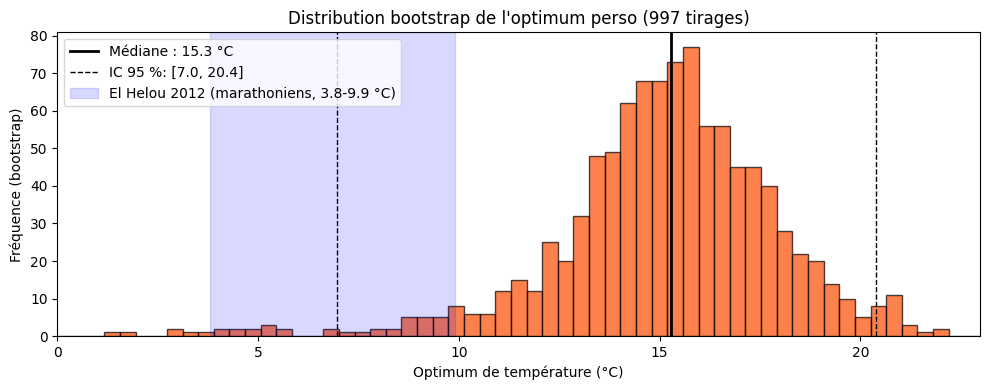

In [17]:
from scipy import stats

rng = np.random.default_rng(42)
N_BOOT = 1000
n = len(dfm)

optima = np.zeros(N_BOOT)
for b in range(N_BOOT):
    idx = rng.integers(0, n, size=n)
    sample = dfm.iloc[idx]
    try:
        m = smf.ols(formula, data=sample).fit()
        b1 = m.params["weather_temperature"]
        b2 = m.params["I(weather_temperature ** 2)"]
        if b2 > 0:  # parabole convexe → vrai minimum
            optima[b] = -b1 / (2 * b2)
        else:
            optima[b] = np.nan
    except Exception:
        optima[b] = np.nan

optima = optima[~np.isnan(optima)]
print(f"Bootstrap : {len(optima)}/{N_BOOT} tirages valides (parabole convexe)")
print(f"Optimum ponctuel : {-model.params['weather_temperature'] / (2*model.params['I(weather_temperature ** 2)']):.2f} °C")
print(f"IC bootstrap 95 % (percentile) : [{np.percentile(optima, 2.5):.2f}, {np.percentile(optima, 97.5):.2f}] °C")
print(f"Médiane bootstrap : {np.median(optima):.2f} °C")

# Histogramme de la distribution bootstrap
fig, ax = plt.subplots(figsize=(10, 4))
# Bornes robustes : 1er et 99e percentile étendus
x_lo = min(0, np.percentile(optima, 1) - 2)
x_hi = np.percentile(optima, 99) + 2
ax.hist(optima, bins=np.linspace(x_lo, x_hi, 60), color="#FC4C02", alpha=0.7, edgecolor="black")
ax.axvline(np.median(optima), color="black", lw=2, label=f"Médiane : {np.median(optima):.1f} °C")
ax.axvline(np.percentile(optima, 2.5), color="black", lw=1, ls="--", label=f"IC 95 %: [{np.percentile(optima, 2.5):.1f}, {np.percentile(optima, 97.5):.1f}]")
ax.axvline(np.percentile(optima, 97.5), color="black", lw=1, ls="--")
ax.axvspan(3.8, 9.9, alpha=0.15, color="blue", label="El Helou 2012 (marathoniens, 3.8-9.9 °C)")
ax.set_xlim(x_lo, x_hi)
ax.set_xlabel("Optimum de température (°C)")
ax.set_ylabel("Fréquence (bootstrap)")
ax.set_title(f"Distribution bootstrap de l'optimum perso ({len(optima)} tirages)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Cook’s distance (outliers influents)

Seuil Cook's distance : 0.0328

8 sorties les plus influentes :
 date_only                            name  distance_km  pace_min_km  weather_temperature  elev_per_km  fitted  resid  cooks_d
2025-12-24          Course à pied matinale        4.623        7.138                  0.2        3.396   5.838  1.300    0.135
2026-08-27         Course à pied en soirée        2.423        6.907                 19.9        6.397   4.888  2.019    0.095
2025-01-10           Course à pied du midi        1.811        4.409                  2.2        8.119   5.608 -1.199    0.073
2025-11-17 Course à pied dans l'après-midi        2.188        7.123                  5.2       22.446   5.795  1.328    0.071
2024-08-12           Course à pied le soir       12.017        5.243                 31.8        3.695   6.001 -0.759    0.067
2024-12-03           Course à pied de nuit        1.100        6.528                  1.6        6.362   5.598  0.930    0.054
2025-03-16          Course à pied matinale     

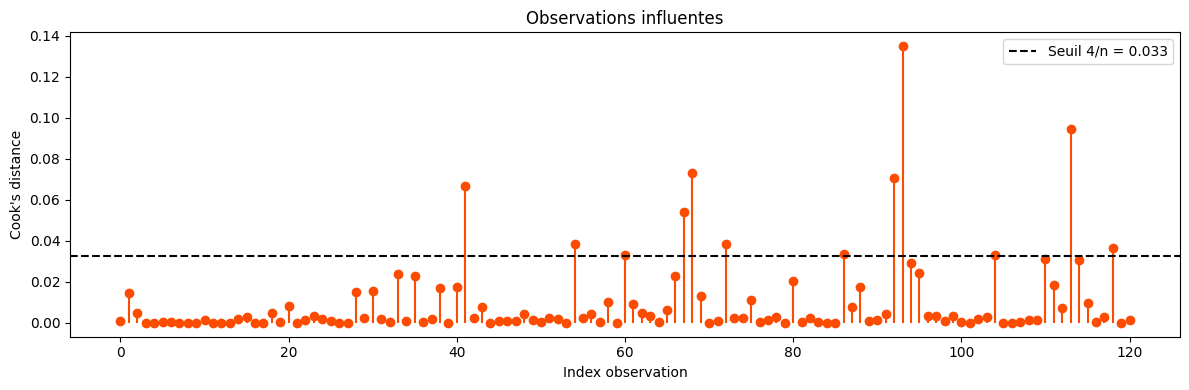

In [16]:
from statsmodels.stats.outliers_influence import OLSInfluence

infl = OLSInfluence(model)
cooks_d = infl.cooks_distance[0]

# Seuil usuel : 4/n
seuil = 4 / len(dfm)
dfm_fit = dfm.loc[model.model.data.row_labels].copy()
dfm_fit["cooks_d"] = cooks_d
dfm_fit["resid"] = model.resid.values
dfm_fit["fitted"] = model.fittedvalues.values

top_influents = dfm_fit.nlargest(8, "cooks_d")[
    ["date_only", "name", "distance_km", "pace_min_km",
     "weather_temperature", "elev_per_km", "fitted", "resid", "cooks_d"]
]
print(f"Seuil Cook's distance : {seuil:.4f}")
print(f"\n8 sorties les plus influentes :")
print(top_influents.round(3).to_string(index=False))

# Figure Cook's distance
fig, ax = plt.subplots(figsize=(12, 4))
ax.stem(range(len(cooks_d)), cooks_d, basefmt=" ", linefmt="#FC4C02", markerfmt="o")
ax.axhline(seuil, color="black", ls="--", label=f"Seuil 4/n = {seuil:.3f}")
ax.set_xlabel("Index observation")
ax.set_ylabel("Cook's distance")
ax.set_title("Observations influentes")
ax.legend()
plt.tight_layout()
plt.show()

Test placebo (shuffle)


=== PLACEBO : pace shufflée ===
241/500 tirages valides
Médiane T° observée dans les données : 17.20 °C
Médiane T° pondérée (centre de masse) : 16.74 °C
Optimum réel (modèle fit) : 15.73 °C
Optimum PLACEBO médiane : 14.98 °C
Optimum PLACEBO IC 95 % : [-27.82, 55.72] °C


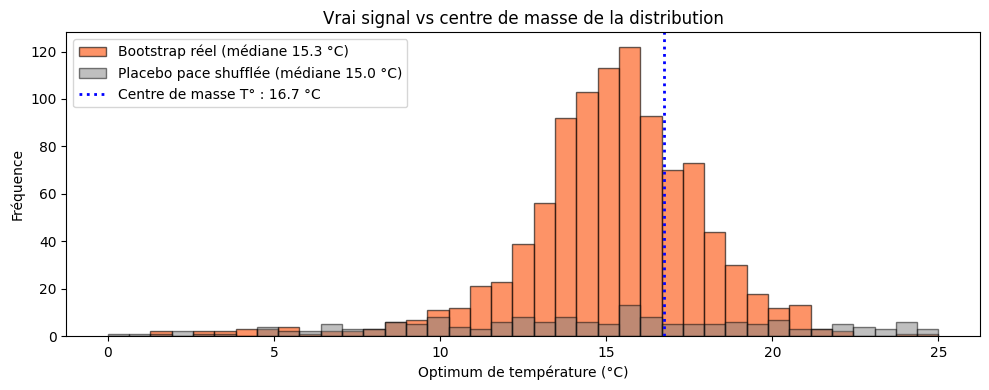

In [18]:
# Test placebo : si on casse le lien pace↔T°, où tombe l'optimum sous H0 ?
rng2 = np.random.default_rng(123)
N_PLACEBO = 500
optima_h0 = []

for b in range(N_PLACEBO):
    sample = dfm.copy()
    sample["pace_min_km"] = rng2.permutation(sample["pace_min_km"].values)
    try:
        m = smf.ols(formula, data=sample).fit()
        b1 = m.params["weather_temperature"]
        b2 = m.params["I(weather_temperature ** 2)"]
        if b2 > 0:
            optima_h0.append(-b1 / (2 * b2))
    except Exception:
        pass

optima_h0 = np.array(optima_h0)
print(f"\n=== PLACEBO : pace shufflée ===")
print(f"{len(optima_h0)}/{N_PLACEBO} tirages valides")
print(f"Médiane T° observée dans les données : {dfm['weather_temperature'].median():.2f} °C")
print(f"Médiane T° pondérée (centre de masse) : {dfm['weather_temperature'].mean():.2f} °C")
print(f"Optimum réel (modèle fit) : 15.73 °C")
print(f"Optimum PLACEBO médiane : {np.median(optima_h0):.2f} °C")
print(f"Optimum PLACEBO IC 95 % : [{np.percentile(optima_h0, 2.5):.2f}, {np.percentile(optima_h0, 97.5):.2f}] °C")

# Figure comparant la vraie distribution et la placebo
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 25, 40)
ax.hist(optima, bins=bins, color="#FC4C02", alpha=0.6, edgecolor="black",
        label=f"Bootstrap réel (médiane {np.median(optima):.1f} °C)")
ax.hist(optima_h0, bins=bins, color="gray", alpha=0.5, edgecolor="black",
        label=f"Placebo pace shufflée (médiane {np.median(optima_h0):.1f} °C)")
ax.axvline(dfm["weather_temperature"].mean(), color="blue", lw=2, ls=":",
           label=f"Centre de masse T° : {dfm['weather_temperature'].mean():.1f} °C")
ax.set_xlabel("Optimum de température (°C)")
ax.set_ylabel("Fréquence")
ax.set_title("Vrai signal vs centre de masse de la distribution")
ax.legend()
plt.tight_layout()
plt.show()

Test F quadratique vs linéaire

In [19]:
# Modèle linéaire (sans T²)
formula_lin = (
    "pace_min_km ~ weather_temperature "
    "+ weather_humidity + distance_km + elev_per_km "
    "+ vol_30d_km + days_since_last"
)
model_lin = smf.ols(formula_lin, data=dfm).fit()

print("=== Comparaison modèle avec/sans T² ===")
print(f"Linéaire       : R² = {model_lin.rsquared:.4f}, R² adj = {model_lin.rsquared_adj:.4f}, AIC = {model_lin.aic:.2f}")
print(f"Quadratique    : R² = {model.rsquared:.4f}, R² adj = {model.rsquared_adj:.4f}, AIC = {model.aic:.2f}")

# Test F : le quadratique ajoute-t-il significativement ?
from scipy.stats import f as f_dist
rss_lin = (model_lin.resid ** 2).sum()
rss_quad = (model.resid ** 2).sum()
df_num = 1  # 1 paramètre ajouté (T²)
df_den = len(dfm) - 8
f_stat = ((rss_lin - rss_quad) / df_num) / (rss_quad / df_den)
p_val = 1 - f_dist.cdf(f_stat, df_num, df_den)
print(f"\nTest F (ajout de T²) : F = {f_stat:.3f}, p = {p_val:.4f}")
print(f"Conclusion : {'quadratique significativement meilleur' if p_val < 0.05 else 'linéaire suffit'}")

=== Comparaison modèle avec/sans T² ===
Linéaire       : R² = 0.0938, R² adj = 0.0461, AIC = 290.18
Quadratique    : R² = 0.1816, R² adj = 0.1309, AIC = 279.85

Test F (ajout de T²) : F = 12.220, p = 0.0007
Conclusion : quadratique significativement meilleur


Pace prédite vs T° avec IC bootstrap

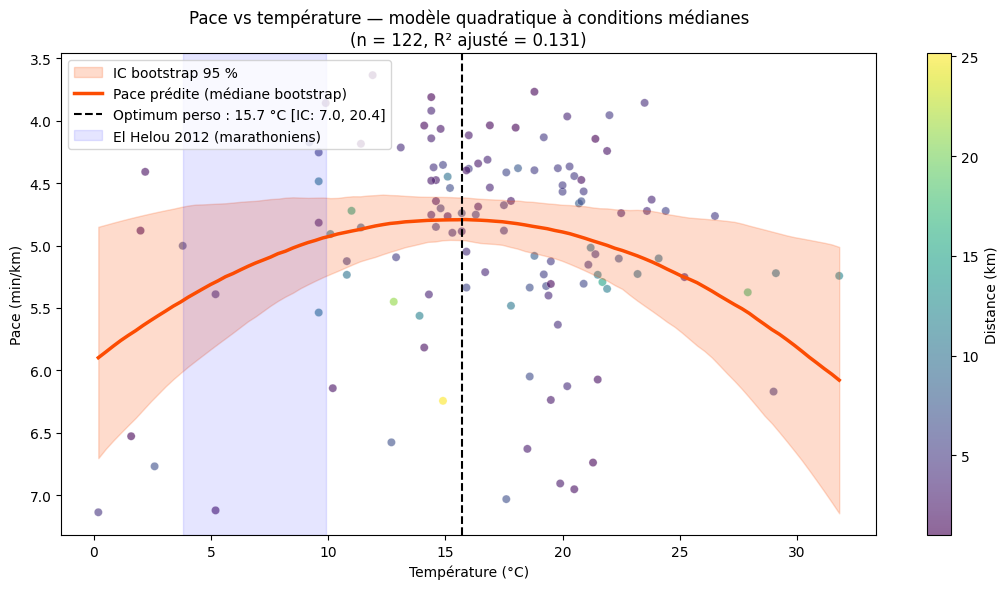

Figure sauvegardée dans docs/figures/07_pace_vs_T_IC.png


In [21]:
# Grille de T° pour prédiction, autres variables fixées à leur médiane
T_grid = np.linspace(dfm["weather_temperature"].min(),
                     dfm["weather_temperature"].max(), 100)

# Prédictions bootstrap de la courbe
N_CURVES = 500
curves = np.zeros((N_CURVES, len(T_grid)))
rng3 = np.random.default_rng(2026)

med_hum = dfm["weather_humidity"].median()
med_dist = dfm["distance_km"].median()
med_elev = dfm["elev_per_km"].median()
med_vol = dfm["vol_30d_km"].median()
med_days = dfm["days_since_last"].median()

for b in range(N_CURVES):
    idx = rng3.integers(0, len(dfm), size=len(dfm))
    sample = dfm.iloc[idx]
    try:
        m = smf.ols(formula, data=sample).fit()
        pred = (m.params["Intercept"]
                + m.params["weather_temperature"] * T_grid
                + m.params["I(weather_temperature ** 2)"] * T_grid**2
                + m.params["weather_humidity"] * med_hum
                + m.params["distance_km"] * med_dist
                + m.params["elev_per_km"] * med_elev
                + m.params["vol_30d_km"] * med_vol
                + m.params["days_since_last"] * med_days)
        curves[b] = pred
    except Exception:
        curves[b] = np.nan

# Enveloppe IC 95 %
lo = np.nanpercentile(curves, 2.5, axis=0)
hi = np.nanpercentile(curves, 97.5, axis=0)
med_curve = np.nanmedian(curves, axis=0)

# Figure
fig, ax = plt.subplots(figsize=(11, 6))

# Nuage de points colorés par distance
sc = ax.scatter(dfm["weather_temperature"], dfm["pace_min_km"],
                c=dfm["distance_km"], cmap="viridis", alpha=0.6, s=35,
                edgecolor="white", linewidth=0.3)
cbar = plt.colorbar(sc, ax=ax, label="Distance (km)")

# Courbe médiane + IC
ax.fill_between(T_grid, lo, hi, color="#FC4C02", alpha=0.2, label="IC bootstrap 95 %")
ax.plot(T_grid, med_curve, color="#FC4C02", lw=2.5, label="Pace prédite (médiane bootstrap)")

# Optimum
opt_T = 15.73
ax.axvline(opt_T, color="black", lw=1.5, ls="--",
           label=f"Optimum perso : {opt_T:.1f} °C [IC: 7.0, 20.4]")

# Zone El Helou
ax.axvspan(3.8, 9.9, alpha=0.1, color="blue",
           label="El Helou 2012 (marathoniens)")

ax.set_xlabel("Température (°C)")
ax.set_ylabel("Pace (min/km)")
ax.set_title("Pace vs température — modèle quadratique à conditions médianes\n"
             f"(n = {len(dfm)}, R² ajusté = {model.rsquared_adj:.3f})")
ax.legend(loc="upper left")
ax.invert_yaxis()  # pace plus rapide = plus haut
plt.tight_layout()
plt.show()

# Sauvegarde pour la note Quost
fig.savefig("../docs/figures/07_pace_vs_T_IC.png", dpi=150, bbox_inches="tight")
print("Figure sauvegardée dans docs/figures/07_pace_vs_T_IC.png")

Décomposition : météo seule vs modèle complet

In [22]:
# Modèle 1 : météo seule (T° + T² + humidité)
f_meteo = "pace_min_km ~ weather_temperature + I(weather_temperature**2) + weather_humidity"

# Modèle 2 : effort seul (distance + elev_per_km)
f_effort = "pace_min_km ~ distance_km + elev_per_km"

# Modèle 3 : forme seule (vol_30d + days_since_last)
f_forme = "pace_min_km ~ vol_30d_km + days_since_last"

# Modèle 4 : météo + effort (sans forme)
f_meteo_eff = ("pace_min_km ~ weather_temperature + I(weather_temperature**2) "
               "+ weather_humidity + distance_km + elev_per_km")

# Modèle complet (déjà fait = model)
models = {
    "Météo seule (T, T², hum)": smf.ols(f_meteo, data=dfm).fit(),
    "Effort seul (dist, D+/km)": smf.ols(f_effort, data=dfm).fit(),
    "Forme seule (vol30, days)": smf.ols(f_forme, data=dfm).fit(),
    "Météo + Effort":            smf.ols(f_meteo_eff, data=dfm).fit(),
    "Complet (7 variables)":     model,
}

print(f"{'Modèle':<30} {'R²':>7} {'R² adj':>8} {'RMSE s/km':>10} {'AIC':>8}")
print("-" * 70)
for name, m in models.items():
    rmse_s = np.sqrt(m.mse_resid) * 60
    print(f"{name:<30} {m.rsquared:>7.3f} {m.rsquared_adj:>8.3f} {rmse_s:>10.1f} {m.aic:>8.1f}")

Modèle                              R²   R² adj  RMSE s/km      AIC
----------------------------------------------------------------------
Météo seule (T, T², hum)         0.096    0.074       46.1    285.7
Effort seul (dist, D+/km)        0.085    0.070       46.2    285.2
Forme seule (vol30, days)        0.008   -0.009       48.2    293.2
Météo + Effort                   0.175    0.140       44.4    278.6
Complet (7 variables)            0.182    0.131       44.7    279.9


Refit propre du modèle final “Météo + Effort”

In [23]:
formula_final = (
    "pace_min_km ~ weather_temperature + I(weather_temperature**2) "
    "+ weather_humidity + distance_km + elev_per_km"
)

model_final = smf.ols(formula_final, data=dfm).fit()
print(model_final.summary())

# Chiffres clés
print(f"\n=== Modèle final retenu ===")
print(f"n = {len(dfm)}")
print(f"R² = {model_final.rsquared:.3f}, R² adj = {model_final.rsquared_adj:.3f}")
print(f"RMSE = {np.sqrt(model_final.mse_resid):.3f} min/km = {np.sqrt(model_final.mse_resid)*60:.1f} s/km")
print(f"Durbin-Watson : {durbin_watson(model_final.resid):.3f}")

# Nouvel optimum T° (avec coefs du modèle final)
b1 = model_final.params["weather_temperature"]
b2 = model_final.params["I(weather_temperature ** 2)"]
T_opt_final = -b1 / (2 * b2)
print(f"\nOptimum T° (modèle final) : {T_opt_final:.2f} °C")

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     4.928
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           0.000398
Time:                        23:18:04   Log-Likelihood:                -133.31
No. Observations:                 122   AIC:                             278.6
Df Residuals:                     116   BIC:                             295.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

Effet T° quantifié en termes concrets

In [24]:
# Calcul de la pace prédite à conditions médianes pour une grille de T°
med_hum = dfm["weather_humidity"].median()
med_dist = dfm["distance_km"].median()
med_elev = dfm["elev_per_km"].median()

def pace_at_T(T):
    return (model_final.params["Intercept"]
            + model_final.params["weather_temperature"] * T
            + model_final.params["I(weather_temperature ** 2)"] * T**2
            + model_final.params["weather_humidity"] * med_hum
            + model_final.params["distance_km"] * med_dist
            + model_final.params["elev_per_km"] * med_elev)

# Table d'effet : pace à T°, écart vs optimum
T_points = [0, 5, 10, 15, 20, 25, 30]
rows = []
pace_opt = pace_at_T(T_opt_final)
for T in T_points:
    p = pace_at_T(T)
    delta_sec = (p - pace_opt) * 60
    rows.append({"T (°C)": T, "pace (min/km)": f"{p:.2f}",
                 "pace (min:ss)": f"{int(p)}:{int(round((p - int(p))*60)):02d}",
                 "écart vs optimum (s/km)": f"+{delta_sec:.0f}"})

print(f"Effet de la T° sur ma pace (conditions médianes, optimum {T_opt_final:.1f} °C) :")
print(pd.DataFrame(rows).to_string(index=False))

# Effets locaux : dérivée en quelques points
print("\nSensibilité locale (dérivée dpace/dT°) :")
for T in [5, 10, 15, 20, 25]:
    deriv = b1 + 2 * b2 * T  # min/km par °C
    print(f"  à {T} °C : {deriv*60:+.1f} s/km par °C")

Effet de la T° sur ma pace (conditions médianes, optimum 16.2 °C) :
 T (°C) pace (min/km) pace (min:ss) écart vs optimum (s/km)
      0          5.94          5:56                     +70
      5          5.32          5:19                     +34
     10          4.94          4:56                     +10
     15          4.77          4:46                      +0
     20          4.83          4:50                      +4
     25          5.11          5:07                     +21
     30          5.61          5:37                     +51

Sensibilité locale (dérivée dpace/dT°) :
  à 5 °C : -6.0 s/km par °C
  à 10 °C : -3.3 s/km par °C
  à 15 °C : -0.6 s/km par °C
  à 20 °C : +2.0 s/km par °C
  à 25 °C : +4.7 s/km par °C


Virer humidité : modèle à 4 variables

In [25]:
f_minimal = ("pace_min_km ~ weather_temperature + I(weather_temperature**2) "
             "+ distance_km + elev_per_km")
model_min = smf.ols(f_minimal, data=dfm).fit()

print(f"=== Comparaison modèles ===")
print(f"{'Modèle':<40} {'R² adj':>8} {'RMSE s/km':>10} {'AIC':>8}")
print("-" * 70)
print(f"{'4 var (T, T², dist, D+/km)':<40} {model_min.rsquared_adj:>8.3f} {np.sqrt(model_min.mse_resid)*60:>10.1f} {model_min.aic:>8.1f}")
print(f"{'5 var (+ humidité)':<40} {model_final.rsquared_adj:>8.3f} {np.sqrt(model_final.mse_resid)*60:>10.1f} {model_final.aic:>8.1f}")
print(f"{'7 var (+ vol_30d, days_since_last)':<40} {model.rsquared_adj:>8.3f} {np.sqrt(model.mse_resid)*60:>10.1f} {model.aic:>8.1f}")

b1m = model_min.params["weather_temperature"]
b2m = model_min.params["I(weather_temperature ** 2)"]
print(f"\nOptimum T° (modèle 4 var) : {-b1m/(2*b2m):.2f} °C")
print(f"Coefs : T = {b1m:.4f} (p={model_min.pvalues['weather_temperature']:.3f}), "
      f"T² = {b2m:.5f} (p={model_min.pvalues['I(weather_temperature ** 2)']:.3f})")

=== Comparaison modèles ===
Modèle                                     R² adj  RMSE s/km      AIC
----------------------------------------------------------------------
4 var (T, T², dist, D+/km)                  0.147       44.2    276.6
5 var (+ humidité)                          0.140       44.4    278.6
7 var (+ vol_30d, days_since_last)          0.131       44.7    279.9

Optimum T° (modèle 4 var) : 16.26 °C
Coefs : T = -0.1449 (p=0.001), T² = 0.00445 (p=0.001)


Bonus : FC en supplémentaire sur l’ACP

Variance expliquée : [0.226 0.19  0.16 ]

n sorties avec FC : 13
  Corrélation FC moyenne ↔ PC1 : +0.776
  Corrélation FC moyenne ↔ PC2 : -0.050
  Corrélation FC moyenne ↔ PC3 : -0.433


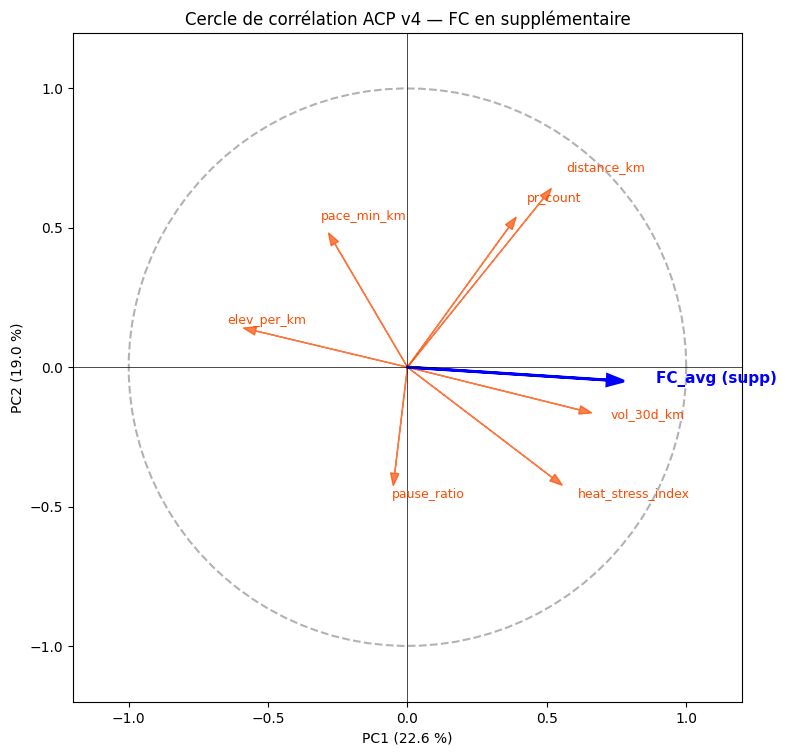

In [26]:
# Charger les loadings et scores de l'ACP v4 depuis le notebook 05
# Si tu as déjà la projection ACP v4 en mémoire ou sur disque, utilise-la directement
# Sinon on refait rapidement :

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

ACTIVE_V4 = ["distance_km", "pace_min_km", "elev_per_km", "pause_ratio",
             "pr_count", "weather_temperature", "vol_30d_km"]

# Recalculer heat_stress_index pour cohérence v4 (gardé en var active dans ACP)
dfm["heat_stress_index"] = dfm["weather_temperature"] * (1 + dfm["weather_humidity"] / 100)
ACTIVE_V4_HSI = ["distance_km", "pace_min_km", "elev_per_km", "pause_ratio",
                 "pr_count", "heat_stress_index", "vol_30d_km"]

X_act = dfm[ACTIVE_V4_HSI].dropna()
scaler = StandardScaler()
X_std = scaler.fit_transform(X_act)
pca = PCA(n_components=3)
scores = pca.fit_transform(X_std)
print("Variance expliquée :", np.round(pca.explained_variance_ratio_, 3))

# FC en supplémentaire : corrélation avec les scores
# Attention : seulement les 13 sorties avec HR
has_hr = dfm.loc[X_act.index, "average_heartrate"].notna()
hr = dfm.loc[X_act.index, "average_heartrate"]
print(f"\nn sorties avec FC : {has_hr.sum()}")

for i in range(3):
    corr = np.corrcoef(scores[has_hr.values, i], hr[has_hr].values)[0, 1]
    print(f"  Corrélation FC moyenne ↔ PC{i+1} : {corr:+.3f}")

# Projection dans le cercle de corrélation
# Coordonnée de FC dans le cercle = corr avec chaque PC
hr_proj = [np.corrcoef(scores[has_hr.values, i], hr[has_hr].values)[0, 1] for i in range(2)]

# Figure cercle de corrélation PC1-PC2 avec variables actives + FC supp
fig, ax = plt.subplots(figsize=(8, 8))
# Cercle unité
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), "k--", alpha=0.3)
ax.axhline(0, color="k", lw=0.5)
ax.axvline(0, color="k", lw=0.5)

# Variables actives (loadings)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
for i, var in enumerate(ACTIVE_V4_HSI):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1], color="#FC4C02",
             head_width=0.03, length_includes_head=True, alpha=0.7)
    ax.text(loadings[i, 0]*1.1, loadings[i, 1]*1.1, var, fontsize=9, color="#FC4C02")

# FC en supplémentaire
ax.arrow(0, 0, hr_proj[0], hr_proj[1], color="blue",
         head_width=0.04, length_includes_head=True, lw=2)
ax.text(hr_proj[0]*1.15, hr_proj[1]*1.15, "FC_avg (supp)", fontsize=11,
        color="blue", fontweight="bold")

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")
ax.set_title("Cercle de corrélation ACP v4 — FC en supplémentaire")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Figure finale pace-T° avec modèle 4 var

Optimum modèle 4 var : 16.26 °C, IC 95 % [10.7, 18.7]


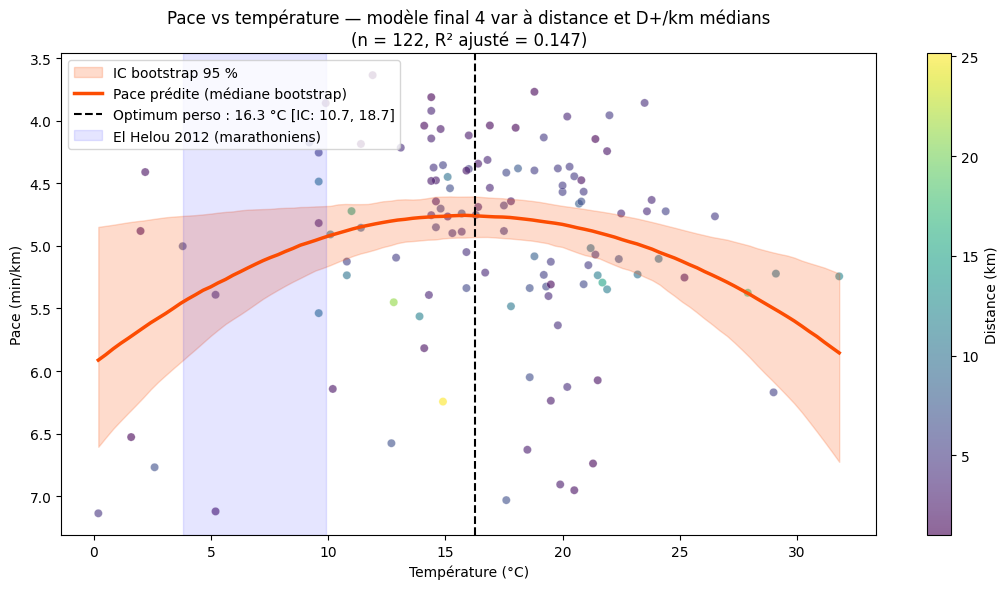

Figure finale sauvegardée.


In [27]:
# Re-bootstrap avec modèle 4 var
rng4 = np.random.default_rng(2027)
N_CURVES = 500
T_grid = np.linspace(dfm["weather_temperature"].min(),
                     dfm["weather_temperature"].max(), 100)
curves = np.zeros((N_CURVES, len(T_grid)))

med_dist = dfm["distance_km"].median()
med_elev = dfm["elev_per_km"].median()

for b in range(N_CURVES):
    idx = rng4.integers(0, len(dfm), size=len(dfm))
    sample = dfm.iloc[idx]
    try:
        m = smf.ols(f_minimal, data=sample).fit()
        pred = (m.params["Intercept"]
                + m.params["weather_temperature"] * T_grid
                + m.params["I(weather_temperature ** 2)"] * T_grid**2
                + m.params["distance_km"] * med_dist
                + m.params["elev_per_km"] * med_elev)
        curves[b] = pred
    except Exception:
        curves[b] = np.nan

# Bootstrap de l'optimum (modèle 4 var)
opt4 = []
for b in range(N_CURVES):
    idx = rng4.integers(0, len(dfm), size=len(dfm))
    try:
        m = smf.ols(f_minimal, data=dfm.iloc[idx]).fit()
        bb1 = m.params["weather_temperature"]
        bb2 = m.params["I(weather_temperature ** 2)"]
        if bb2 > 0:
            opt4.append(-bb1 / (2 * bb2))
    except Exception:
        pass
opt4 = np.array(opt4)
ic_lo, ic_hi = np.percentile(opt4, [2.5, 97.5])
print(f"Optimum modèle 4 var : {-b1m/(2*b2m):.2f} °C, IC 95 % [{ic_lo:.1f}, {ic_hi:.1f}]")

# Figure
lo = np.nanpercentile(curves, 2.5, axis=0)
hi = np.nanpercentile(curves, 97.5, axis=0)
med_curve = np.nanmedian(curves, axis=0)

fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(dfm["weather_temperature"], dfm["pace_min_km"],
                c=dfm["distance_km"], cmap="viridis", alpha=0.6, s=35,
                edgecolor="white", linewidth=0.3)
plt.colorbar(sc, ax=ax, label="Distance (km)")

ax.fill_between(T_grid, lo, hi, color="#FC4C02", alpha=0.2, label="IC bootstrap 95 %")
ax.plot(T_grid, med_curve, color="#FC4C02", lw=2.5, label="Pace prédite (médiane bootstrap)")

opt_T = -b1m / (2*b2m)
ax.axvline(opt_T, color="black", lw=1.5, ls="--",
           label=f"Optimum perso : {opt_T:.1f} °C [IC: {ic_lo:.1f}, {ic_hi:.1f}]")
ax.axvspan(3.8, 9.9, alpha=0.1, color="blue", label="El Helou 2012 (marathoniens)")

ax.set_xlabel("Température (°C)")
ax.set_ylabel("Pace (min/km)")
ax.set_title(f"Pace vs température — modèle final 4 var à distance et D+/km médians\n"
             f"(n = {len(dfm)}, R² ajusté = {model_min.rsquared_adj:.3f})")
ax.legend(loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

fig.savefig("../docs/figures/07_pace_vs_T_final_4var.png", dpi=150, bbox_inches="tight")
print("Figure finale sauvegardée.")

Résidus par saison

Résidus par saison (modèle 4 var) :
           count   mean    std
season                        
Automne       29 -0.108  0.777
Hiver          7  0.326  0.975
Printemps     28 -0.098  0.466
Été           58  0.062  0.766


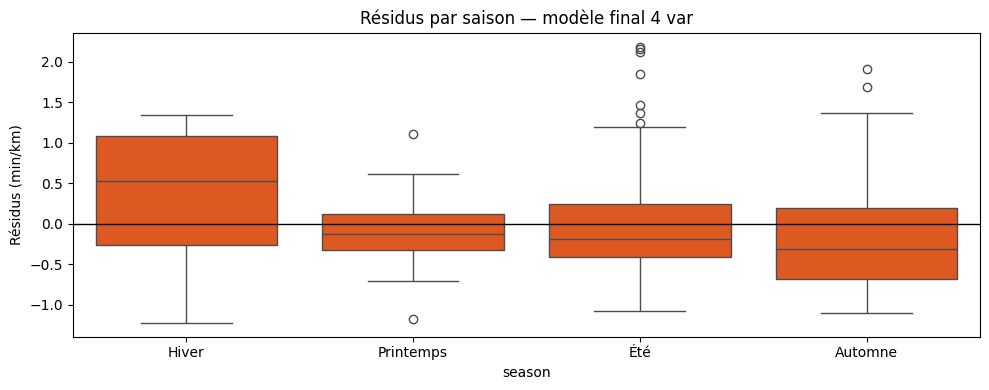

In [28]:
dfm_fit = dfm.loc[model_min.model.data.row_labels].copy()
dfm_fit["resid"] = model_min.resid.values
dfm_fit["month"] = dfm_fit["date_only"].dt.month
dfm_fit["season"] = dfm_fit["month"].map(lambda m: 
    "Hiver" if m in [12,1,2] else "Printemps" if m in [3,4,5]
    else "Été" if m in [6,7,8] else "Automne")

print("Résidus par saison (modèle 4 var) :")
print(dfm_fit.groupby("season")["resid"].agg(["count", "mean", "std"]).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
import seaborn as sns
sns.boxplot(data=dfm_fit, x="season", y="resid",
            order=["Hiver", "Printemps", "Été", "Automne"],
            color="#FC4C02", ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Résidus (min/km)")
ax.set_title("Résidus par saison — modèle final 4 var")
plt.tight_layout()
plt.show()

Test confusion : modèle naïf vs contrôlé

In [29]:
# Modèle naïf : T° seule (pas de contrôle)
f_naif = "pace_min_km ~ weather_temperature + I(weather_temperature**2)"
model_naif = smf.ols(f_naif, data=dfm).fit()

b1n = model_naif.params["weather_temperature"]
b2n = model_naif.params["I(weather_temperature ** 2)"]
if b2n > 0:
    opt_naif = -b1n / (2*b2n)
    print(f"Modèle naïf (T° seule, pas de contrôle) :")
    print(f"  Optimum : {opt_naif:.2f} °C")
    print(f"  R² = {model_naif.rsquared:.3f}")
else:
    print(f"Modèle naïf : parabole concave (b2={b2n:.5f}), pas d'optimum.")
    print(f"  R² = {model_naif.rsquared:.3f}")

print(f"\nModèle contrôlé 4 var :")
print(f"  Optimum : {-b1m/(2*b2m):.2f} °C")
print(f"  R² = {model_min.rsquared:.3f}")

# Corrélation T° ↔ distance pour mesurer la confusion
r_td = np.corrcoef(dfm["weather_temperature"], dfm["distance_km"])[0, 1]
print(f"\nCorrélation T° ↔ distance : r = {r_td:.3f}")
print(f"(une corrélation négative = sorties plus longues en hiver, source de confusion)")

Modèle naïf (T° seule, pas de contrôle) :
  Optimum : 16.45 °C
  R² = 0.096

Modèle contrôlé 4 var :
  Optimum : 16.26 °C
  R² = 0.175

Corrélation T° ↔ distance : r = 0.129
(une corrélation négative = sorties plus longues en hiver, source de confusion)
